# Quoting paths and expanding globs

Count bytes in three files whose names contain spaces.

A quoted parameter expands to one argument even if its value contains spaces. A pathname pattern expands to matching pathnames. Keep the pattern outside the quotes while quoting its directory prefix.

In [1]:
from pathlib import Path
import shutil, subprocess, tempfile
import matplotlib.pyplot as plt
import numpy as np

here = Path.cwd()

## Native source

`example.sh`

```sh
#!/bin/sh
set -eu
export LC_ALL=C
mkdir files
printf %s alpha > "files/first file"
printf %s beta > "files/second file"
printf %s cc > "files/third file"
for file in files/*; do
    wc -c < "$file"
done
```

## Run the shell script

The Python driver gives each installed shell its own empty working directory. Each run must agree with the independently specified fixture.

In [2]:
expected = [5, 4, 2]
shells = [name for name in ("sh", "bash", "zsh") if shutil.which(name)]
runs = {}
for shell in shells:
    with tempfile.TemporaryDirectory() as directory:
        result = subprocess.run(
            [shell, str(here / "example.sh")],
            cwd=directory,
            check=True,
            capture_output=True,
            text=True,
        )
    numbers = [int(v) for v in result.stdout.split()]
    runs[shell] = numbers
    print(shell, numbers)
    assert numbers == expected
observed = runs[shells[0]]

sh [5, 4, 2]
bash [5, 4, 2]
zsh [5, 4, 2]


## Inspect the outcome

A filename is data. A shell variable used as a filename should normally be quoted.

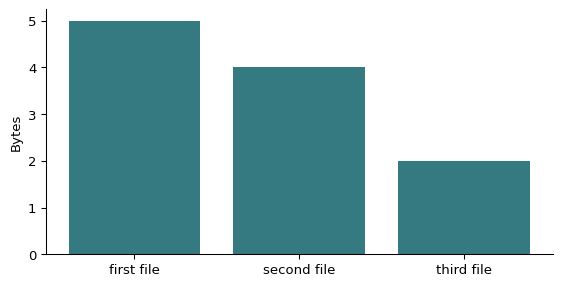

In [3]:
fig, ax = plt.subplots(figsize=(5.8, 2.9), constrained_layout=True)
ax.bar(["first file", "second file", "third file"], observed, color="#357a80")
ax.set(ylabel="Bytes")
plt.show()

## Interpreting the result

A filename is data. A shell variable used as a filename should normally be quoted.

## Exercise

Add a filename containing brackets and run the example without changing the command.

## References

[The Open Group, POSIX shell command language](https://pubs.opengroup.org/onlinepubs/9799919799/utilities/V3_chap02.html)

[GNU Bash reference manual](https://www.gnu.org/software/bash/manual/bash.html)

[Apple Terminal User Guide](https://support.apple.com/guide/terminal/welcome-trml2df0220c/mac)